# Theory First, AI Second: Aspect-Based Sentiment Analysis of Online Reviews
**EMEA CHRIE Research Webinar, 23 October 2026. Jeong-Yeol Park, Ph.D., University of Central Florida**

This notebook runs the full workflow from the webinar on the Maple City dataset, a synthetic set of 11,010 restaurant reviews from *Analyzing Online Reviews with AI* (2026). Maple City is fictional and free to reuse.

The model is the restaurant quality model of Chapter 10 of the book: **food, service and atmospheric quality raise satisfaction, and satisfaction raises the intention to return.** Every construct is measured from the review text.

Each step shows **the prompt you can type into Gemini in Colab** and the code that the prompt produces. You can run the code as is, or type the prompt and compare.

**Steps**
1. Load and clean the reviews
2. Split reviews into sentences
3. Assign sentences to constructs with the book's keyword lists (unigrams), then (3b) refine them with bigrams
4. Judge each sentence three ways: (a) VADER lexicon, (b) Gemini, (c) an ABSA model (DeBERTa-v3)
5. Check the assignment and the judgments against a hand-coded sample
6. Build review-level construct scores
7. Estimate the Chapter 10 model under each measurement and compare the paths

## Setup
Upload two files when asked, or drop them into the Files panel first: `maple_city_reviews.csv` and `reference_coding_150.csv`. The ABSA step (4c) downloads a model from Hugging Face the first time (about 0.7 GB).

In [1]:
!pip -q install vaderSentiment
import re, json, os, numpy as np, pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import nltk
for p in ["wordnet", "stopwords", "averaged_perceptron_tagger_eng", "averaged_perceptron_tagger"]:
    nltk.download(p, quiet=True)
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from google.colab import files
if not all(os.path.exists(f) for f in ["maple_city_reviews.csv", "reference_coding_150.csv"]):
    uploaded = files.upload()   # skipped when the files are already in the Files panel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 2.0 MB/s eta 0:00:00


## Step 1. Load and clean
> **Gemini prompt:** "Load maple_city_reviews.csv into a DataFrame called reviews. Remove duplicate reviews of the same restaurant and drop reviews shorter than 3 words. Show how many rows remain after each step."

In [2]:
reviews = pd.read_csv("maple_city_reviews.csv")
print("Loaded:", len(reviews))
reviews = reviews.drop_duplicates(subset=["business_id", "text"])
print("After removing duplicates:", len(reviews))
reviews = reviews[reviews.text.str.split().str.len() >= 3]
print("After removing short reviews:", len(reviews))
reviews["year"] = reviews.date.str[:4].astype(int)
reviews.head()

Loaded: 11010
After removing duplicates: 11010
After removing short reviews: 11010


,review_id,business_id,date,stars,useful,text,year
0,R004567,B0078,2021-06-07 16:00:00,5,5,"Immaculate, fresh restrooms. Dirty floors and ...",2021
1,R006607,B0117,2019-02-19 16:00:00,5,7,Met family here for a celebration. The dining ...,2019
2,R005904,B0102,2021-08-17 09:00:00,5,8,Grabbed lunch here. Incredible flavor in every...,2021
3,R003216,B0057,2019-04-09 09:00:00,1,6,Visited last week. Overpriced for what you get...,2019
4,R010856,B0198,2019-03-13 11:00:00,3,10,Met family here for a celebration. Very reason...,2019


## Step 2. Split reviews into sentences
A guest can praise the food and complain about the service in the same review. Splitting into sentences keeps these judgments apart.
> **Gemini prompt:** "Split each review into sentences and make a new DataFrame called sents with one row per sentence. Keep review_id, business_id, and stars."

In [3]:
sents = (reviews.assign(sentence=reviews.text.str.strip().str.split(r"(?<=[.!?])\s+"))
         .explode("sentence")[["review_id", "business_id", "stars", "sentence"]]
         .reset_index(drop=True))
print(len(sents), "sentences,", round(len(sents) / len(reviews), 1), "per review")
sents.head(8)

132149 sentences, 12.0 per review


,review_id,business_id,stars,sentence
0,R004567,B0078,5,"Immaculate, fresh restrooms."
1,R004567,B0078,5,Dirty floors and dusty surfaces.
2,R004567,B0078,5,The pizza was delicious.
3,R004567,B0078,5,Knowledgeable and helpful waiter.
4,R004567,B0078,5,The pizza was bland and forgettable.
5,R004567,B0078,5,The manager personally checked on us.
6,R004567,B0078,5,Everything tidy and well kept.
7,R004567,B0078,5,A marvellous and memorable highlight.


## Step 3. Constructs come from theory, not from the AI
The constructs follow the restaurant quality model: **food quality**, **service quality** (including the wait), **atmospheric quality**, **satisfaction**, and **revisit intention**. The keyword lists are the ones published with Chapter 10 of the book. A sentence is assigned to a construct when it contains one of its keywords (words are reduced to their dictionary form, so "portions" matches "portion").
> **Gemini prompt:** "Using these keyword lists, add a column called constructs that lists every construct with a keyword in the sentence. Compare lemmatized words, and report the share of sentences with at least one construct."

In [4]:
SPEC = {
 "food": """delicious flavor tasty fresh quality ingredient cooked perfection best dish menu creative tempting portion generous
    satisfying bland forgettable stale reheated overcooked dry greasy flavorless cold limited uninspired tiny stingy burger pizza
    sushi pasta salmon brisket taco latte bowl pad thai bite""",
 "service": """staff server waiter manager hospitality gracious warm friendly attentive welcoming knowledgeable helpful promptly
    quickly fast efficient seated wait waited inattentive ignored dismissive rude careless indifferent slow forever endless line
    reservation turnover check complaint""",
 "atmos": """clean spotless spotlessly immaculate tidy kept dining room floor restroom surface dusty dirty sticky grimy filthy
    unclean neglected space table""",
 "satisfaction": """miserable ordeal regretted awful waste wretched disappointing lackluster forgettable dreary adequate passable
    unremarkable tolerable impressed bothered pleasing satisfied rewarding gratifying comfortable wonderful celebration delighted
    superb treat marvellous memorable highlight""",
 "revisit": """never returning setting foot doubt hesitant second planning soon likely drop certain return definitely coming back
    month visit""",
}
CONSTRUCTS = list(SPEC)
LEM = WordNetLemmatizer()
KW = {c: {LEM.lemmatize(w) for w in s.split()} for c, s in SPEC.items()}
def toks(s): return [LEM.lemmatize(t) for t in re.findall(r"[a-z']+", s.lower())]
def unigrams(s):
    t = toks(s); return {c: [w for w in t if w in KW[c]] for c in CONSTRUCTS if any(w in KW[c] for w in t)}
distinct = pd.Series(sents.sentence.unique(), name="sentence")
times = sents.sentence.value_counts()
print(len(distinct), "distinct sentences")
match_uni = {s: unigrams(s) for s in distinct}
share = times[[s for s in distinct if match_uni[s]]].sum() / len(sents)
print(f"Sentences with at least one construct: {share:.1%}")
pd.DataFrame({"sentence": distinct.head(10), "constructs": [list(match_uni[s]) for s in distinct.head(10)]})

150 distinct sentences
Sentences with at least one construct: 81.5%


,sentence,constructs
0,"Immaculate, fresh restrooms.","[food, atmos]"
1,Dirty floors and dusty surfaces.,[atmos]
2,The pizza was delicious.,[food]
3,Knowledgeable and helpful waiter.,[service]
4,The pizza was bland and forgettable.,"[food, satisfaction]"
5,The manager personally checked on us.,[service]
6,Everything tidy and well kept.,[atmos]
7,A marvellous and memorable highlight.,[satisfaction]
8,A wonderful celebration.,[satisfaction]
9,Certain to return very soon.,[revisit]


## Step 3b. Bigrams keep the context
Some keywords carry more than one meaning. "Table" is in the atmosphere list, but "the staff ignored our table" is about service. "Fresh" is in the food list, but "fresh restrooms" are about the atmosphere. A bigram is two neighboring words, counted after stop words such as "the" and "our" are removed. The bigram shows which meaning is used. An ambiguous word then counts only inside the bigrams that fix its meaning.
> **Gemini prompt:** "Remove stop words and count every bigram (two neighboring words), weighted by how often each sentence is written. Show the 15 most frequent bigrams. Then, for the keywords table, fresh, coming, quality and friendly, show their bigrams and how often each was written."


In [5]:
from collections import Counter
STOP = set(stopwords.words("english"))
def bigrams(s):
    w = [t for t in re.findall(r"[a-z']+", s.lower()) if t not in STOP]
    return [f"{a} {b}" for a, b in zip(w, w[1:])]
bigram_counts = Counter()
for s in distinct:
    for b in bigrams(s): bigram_counts[b] += times[s]
print("Most frequent bigrams:")
print(pd.DataFrame(bigram_counts.most_common(15), columns=["bigram", "times written"]).to_string(index=False))
rows = []
for w in ["table", "fresh", "coming", "quality", "friendly"]:
    for b, n in bigram_counts.most_common():
        if w in b.split() or w + "s" in b.split():
            rows.append({"keyword": w, "in the list for": ", ".join(c for c in CONSTRUCTS if LEM.lemmatize(w) in KW[c]), "bigram": b, "times written": n})
pd.DataFrame(rows).groupby("keyword", sort=False).head(4)


Most frequent bigrams:
          bigram  times written
      checked us           3072
 everything tidy           2329
       tidy well           2329
       well kept           2329
     dining room           2329
   room spotless           2329
immaculate fresh           2303
 fresh restrooms           2303
spotlessly clean           2290
    clean tables           2290
   tables floors           2290
    dirty floors           1992
    floors dusty           1992
  dusty surfaces           1992
 restroom filthy           1985


,keyword,in the list for,bigram,times written
0,table,atmos,clean tables,2290
1,table,atmos,tables floors,2290
2,table,atmos,table sticky,1951
3,table,atmos,ignored table,1399
6,fresh,food,immaculate fresh,2303
7,fresh,food,fresh restrooms,2303
8,fresh,food,fresh high,1202
9,coming,revisit,regretted coming,1188
10,coming,revisit,definitely coming,938
11,coming,revisit,coming back,938


In [6]:
# The bigram dictionary from the webinar. It was built on a random sample of 300 sentences coded by construct (round 1):
#   1. A keyword is ambiguous if it sent a sample sentence to a construct the coding did not give.
#   2. An ambiguous keyword counts only inside the bigrams that keep it in the coded construct.
# A second random sample of 300 sentences (round 2) tested it: 95% of sentences in exactly the right construct, unigrams 85%.
# Both samples are in data/coded_samples_300.csv. With your own data, build on one coded sample and test on another.
AMBIGUOUS = {"celebration", "coming", "forgettable", "fresh", "generous", "portion", "quality", "table", "wonderful"}
BIGRAMS = {"food": ["bland forgettable", "fresh high", "generous satisfying", "high quality", "quality ingredients",
                    "satisfying portions", "stingy portions"],
           "service": ["efficient table", "ignored table", "table turnover"],
           "atmos": ["clean tables", "fresh restrooms", "immaculate fresh", "table sticky", "tables floors"],
           "satisfaction": ["forgettable dreary", "regretted coming", "wonderful celebration"],
           "revisit": ["coming back", "definitely coming"]}
KW_BI = {c: KW[c] - AMBIGUOUS for c in CONSTRUCTS}
def with_bigrams(s):
    t = toks(s); bg = bigrams(s); out = {}
    for c in CONSTRUCTS:
        m = [w for w in t if w in KW_BI[c]] + [b for b in BIGRAMS[c] if b in bg]
        if m: out[c] = m
    return out
match_bi = {s: with_bigrams(s) for s in distinct}
changed = [s for s in distinct if set(match_uni[s]) != set(match_bi[s])]
pd.DataFrame({"sentence": changed, "times written": [times[s] for s in changed],
              "unigrams": [", ".join(match_uni[s]) for s in changed],
              "bigrams": [", ".join(match_bi[s]) for s in changed]}).sort_values("times written", ascending=False)


,sentence,times written,unigrams,bigrams
0,"Immaculate, fresh restrooms.",2303,"food, atmos",atmos
12,Wonderful value for the money.,1475,satisfaction,
6,Affordable given the generous portions.,1463,food,
10,The staff ignored our table.,1399,"service, atmos",service
8,A forgettable and dreary occasion.,1382,"food, satisfaction",satisfaction
7,Steep prices for small portions.,1368,food,
2,Met family here for a celebration.,1343,satisfaction,
4,Far too expensive for the quality.,1289,food,
3,Fast and efficient table turnover.,1256,"service, atmos",service
5,Thoroughly regretted coming here.,1188,"satisfaction, revisit",satisfaction


## Step 4a. Lexicon sentiment with VADER
> **Gemini prompt:** "Score every distinct sentence with the VADER compound score, and add a polarity label: pos if 0.05 or higher, neg if -0.05 or lower, otherwise neu."

In [7]:
vader = SentimentIntensityAnalyzer()
vader_score = {s: vader.polarity_scores(s)["compound"] for s in distinct}
vader_pol = {s: "pos" if v >= .05 else "neg" if v <= -.05 else "neu" for s, v in vader_score.items()}
sents["pol_vader"] = sents.sentence.map(vader_pol)
sents.pol_vader.value_counts()

,count
pol_vader,
neu,49260
pos,45577
neg,37312


## Step 4b. Sentiment with Gemini
Gemini labels each distinct sentence once, and the label is copied to every review that uses the sentence. The prompt defines the labels and asks for JSON so the output can be checked.

In [8]:
from google.colab import ai
PROMPT = '''You are coding restaurant review sentences for a research study.
For each sentence, give the polarity of the opinion it expresses: "pos", "neg", or "neu" (no evaluation, or neither good nor bad).
Judge the meaning of the whole sentence, not single words, and take negations into account.
Return only a JSON list of objects with keys "id" and "polarity", one per sentence, in the same order.

Sentences:
'''
def gemini_label(batch):
    text = PROMPT + "\n".join(f"{i}. {s}" for i, s in batch)
    out = ai.generate_text(text)
    out = out[out.find("["): out.rfind("]") + 1]
    return {int(d["id"]): d["polarity"] for d in json.loads(out)}

items = list(enumerate(distinct))
gem = {}
for k in range(0, len(items), 50):
    gem.update(gemini_label(items[k:k + 50]))
gemini_pol = {s: gem.get(i, "neu") for i, s in items}
sents["pol_gemini"] = sents.sentence.map(gemini_pol)
sents.pol_gemini.value_counts()

,count
pol_gemini,
pos,59327
neg,55268
neu,17554


## Step 4c. Aspect-based sentiment with an ABSA model
An ABSA model judges one target at a time. It reads the sentence and one keyword, and returns the probability that the opinion about **that word** is negative, neutral or positive. We use `yangheng/deberta-v3-base-absa-v1.1`, a DeBERTa-v3 model fine-tuned for aspect sentiment. Score = P(positive) minus P(negative), from -1 to +1. The keyword is the first matching keyword that is a noun (the thing being judged), or the first keyword if none is.
> **Gemini prompt:** "For every distinct sentence and every construct found in it, take the first matching keyword that is a noun, or the first keyword if none is, and use the Hugging Face model yangheng/deberta-v3-base-absa-v1.1 to judge the sentiment toward that word. Do this for both dictionaries (unigrams and bigrams). Add the score P(positive) minus P(negative) and the most likely label."

In [9]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
name = "yangheng/deberta-v3-base-absa-v1.1"
tok = AutoTokenizer.from_pretrained(name)
mdl = AutoModelForSequenceClassification.from_pretrained(name).eval()
def keyword(s, matched):
    tags = {LEM.lemmatize(w.lower()): t for w, t in nltk.pos_tag(re.findall(r"[A-Za-z']+", s))}
    nouns = [w for w in matched if " " not in w and tags.get(w, "").startswith("NN")]
    return nouns[0] if nouns else matched[0]
judged = pd.DataFrame([{"sentence": s, "construct": c, "dictionary": d, "keyword": keyword(s, m)}
                       for d, match in [("unigrams", match_uni), ("bigrams", match_bi)] for s in distinct for c, m in match[s].items()])
todo = judged[["sentence", "keyword"]].drop_duplicates().reset_index(drop=True)
lab = {i: l.lower()[:3] for i, l in mdl.config.id2label.items()}
pos_i = [i for i, l in lab.items() if l == "pos"][0]; neg_i = [i for i, l in lab.items() if l == "neg"][0]
scores, labels = [], []
with torch.no_grad():
    for b in range(0, len(todo), 32):
        c = todo.iloc[b:b + 32]
        enc = tok(list(c.sentence), list(c.keyword), padding=True, truncation=True, return_tensors="pt")
        prob = torch.softmax(mdl(**enc).logits, dim=-1).numpy()
        scores += list(prob[:, pos_i] - prob[:, neg_i]); labels += [lab[i] for i in prob.argmax(1)]
todo["absa_score"] = np.round(scores, 3); todo["absa"] = labels
judged = judged.merge(todo, on=["sentence", "keyword"])
print(len(todo), "sentence-keyword pairs judged")
judged[judged.dictionary == "bigrams"].head(10)

149 sentence-keyword pairs judged


,sentence,construct,dictionary,keyword,absa_score,absa
144,"Immaculate, fresh restrooms.",atmos,bigrams,immaculate,0.901,pos
145,Dirty floors and dusty surfaces.,atmos,bigrams,dirty,-0.933,neg
146,The pizza was delicious.,food,bigrams,pizza,0.988,pos
147,Knowledgeable and helpful waiter.,service,bigrams,waiter,0.996,pos
148,The pizza was bland and forgettable.,food,bigrams,pizza,-0.985,neg
149,The manager personally checked on us.,service,bigrams,manager,0.990,pos
150,Everything tidy and well kept.,atmos,bigrams,tidy,0.996,pos
151,A marvellous and memorable highlight.,satisfaction,bigrams,highlight,0.997,pos
152,A wonderful celebration.,satisfaction,bigrams,wonderful celebration,0.868,pos
153,Certain to return very soon.,revisit,bigrams,certain,0.285,neu


## Step 5. Do not trust AI output blindly: check both steps against a hand-coded sample
`reference_coding_150.csv` holds the hand coding of every distinct sentence in Maple City: the construct it is about and its polarity. With your own data, code a random sample of about 100 to 200 sentences yourself, then compare.
> **Gemini prompt:** "Using reference_coding_150.csv, report for each dictionary (unigrams and bigrams) how many sentences (weighted by times written) were assigned to the wrong construct. Then compare the VADER, Gemini and ABSA labels with the hand-coded polarity, on the sentence-construct pairs that the hand coding confirms. Report percent agreement and Cohen's kappa."


In [10]:
from sklearn.metrics import cohen_kappa_score
ref = pd.read_csv("reference_coding_150.csv").set_index("sentence")
TO_MODEL = {"food": "food", "service": "service", "wait": "service", "clean": "atmos", "overall": "satisfaction", "revisit": "revisit"}
ref["construct_human"] = ref.aspect.map(TO_MODEL)
for d, match in [("unigrams", match_uni), ("bigrams", match_bi)]:
    pr = [(s, c) for s in distinct for c in match[s]]
    wrong = sum(times[s] for s, c in pr if ref.construct_human.get(s) != c); total = sum(times[s] for s, c in pr)
    print(f"{d:9s} wrongly assigned: {wrong:,} of {total:,} ({wrong / total:.1%})")
ok = judged[judged.dictionary == "bigrams"].join(ref, on="sentence")
ok = ok[ok.construct == ok.construct_human].drop_duplicates(["sentence", "construct"])
ok["vader"] = ok.sentence.map(vader_pol); ok["gemini"] = ok.sentence.map(gemini_pol)
print()
for m in ["vader", "gemini", "absa"]:
    print(f"{m:7s} agreement {(ok[m] == ok.polarity).mean():.1%}   kappa {cohen_kappa_score(ok.polarity, ok[m]):.2f}   ({len(ok)} sentence-construct pairs)")
print()
print(ok.groupby("construct")[["vader", "absa", "polarity"]].apply(lambda g: pd.Series({"pairs": len(g), "vader": (g.vader == g.polarity).mean(), "absa": (g.absa == g.polarity).mean()})).round(2))

unigrams  wrongly assigned: 18,410 of 116,650 (15.8%)
bigrams   wrongly assigned: 2,542 of 100,782 (2.5%)

vader   agreement 56.6%   kappa 0.38   (122 sentence-construct pairs)
gemini  agreement 100.0%   kappa 1.00   (122 sentence-construct pairs)
absa    agreement 96.7%   kappa 0.94   (122 sentence-construct pairs)

              pairs  vader  absa
construct                       
atmos           8.0   0.75  1.00
food           67.0   0.49  1.00
revisit         8.0   0.50  0.88
satisfaction   19.0   0.79  0.84
service        20.0   0.55  1.00


## Step 6. Review-level construct scores
Each construct score is the mean judgment of the sentences in the review that name it, as in Chapter 10. We build it five ways so we can see how the measurement changes the model.
> **Gemini prompt:** "For each review and construct, average the sentence scores. Do this for: unigrams with VADER (the book), unigrams with the ABSA score, bigrams with the ABSA score, bigrams with the Gemini label (+1, 0, -1), and the hand coding. Add the overall VADER score of the whole review."

In [11]:
NUM = {"pos": 1, "neg": -1, "neu": 0}
def scores(dictionary, judge):
    if judge == "human":
        m = ref[ref.construct_human.notna()].reset_index()[["sentence", "construct_human", "polarity"]]
        m = m.rename(columns={"construct_human": "construct"}).assign(v=lambda d: d.polarity.map(NUM))
    else:
        m = judged[judged.dictionary == dictionary][["sentence", "construct", "absa_score"]].copy()
        if judge == "absa": m["v"] = m.absa_score
        if judge == "vader": m["v"] = m.sentence.map(vader_score)
        if judge == "gemini": m["v"] = m.sentence.map(gemini_pol).map(NUM)
    x = sents[["review_id", "sentence"]].merge(m[["sentence", "construct", "v"]], on="sentence").groupby(["review_id", "construct"]).v.mean().unstack()
    return reviews[["review_id", "business_id", "year", "text"]].merge(x, on="review_id", how="left")
overall = {r: vader.polarity_scores(t)["compound"] for r, t in zip(reviews.review_id, reviews.text)}
MEASURES = {"Book: unigrams + VADER": ("unigrams", "vader"), "Unigrams + DeBERTa": ("unigrams", "absa"),
            "Bigrams + DeBERTa": ("bigrams", "absa"), "Bigrams + Gemini": ("bigrams", "gemini"), "Hand coding": (None, "human")}
data = {k: scores(*v).assign(vad=lambda d: d.review_id.map(overall)) for k, v in MEASURES.items()}
data["Bigrams + DeBERTa"][["review_id"] + CONSTRUCTS].head()

,review_id,food,service,atmos,satisfaction,revisit
0,R004567,0.0015,0.9930,0.321333,0.932500,0.285
1,R006607,0.0045,-0.9880,0.953000,-0.196667,0.630
2,R005904,0.9590,0.9815,0.985000,0.995000,0.285
3,R003216,NaN,-0.1998,-0.987000,-0.950000,NaN
4,R010856,-0.9915,0.9408,0.973000,0.007000,0.630


## Step 7. Estimate the Chapter 10 model
Satisfaction is regressed on the three qualities and year. Revisit intention is regressed on satisfaction, the three qualities, overall VADER sentiment and year. Scores are standardized, so the paths are comparable across measurements. Standard errors are clustered by restaurant. The indirect effect of each quality is its path to satisfaction times the path from satisfaction to revisit.
> **Gemini prompt:** "For each measurement, keep reviews with all five constructs, standardize the scores, and fit two regressions with year dummies and standard errors clustered by business_id: satisfaction on food, service and atmos, and revisit on satisfaction, food, service, atmos and vad. Make a table of the paths and the indirect effects for every measurement."

In [12]:
def z(x): return (x - x.mean()) / x.std()
rows = []
for name, d in data.items():
    d = d.dropna(subset=CONSTRUCTS).copy()
    for c in CONSTRUCTS + ["vad"]: d[c] = z(d[c])
    cl = {"cov_type": "cluster", "cov_kwds": {"groups": d.business_id}}
    m1 = smf.ols("satisfaction ~ food + service + atmos + C(year)", d).fit(**cl)
    m2 = smf.ols("revisit ~ satisfaction + food + service + atmos + vad + C(year)", d).fit(**cl)
    b = m2.params.satisfaction
    rows.append({"measurement": name, "reviews": len(d),
                 "food -> sat": m1.params.food, "service -> sat": m1.params.service, "atmos -> sat": m1.params.atmos,
                 "sat -> revisit": b, "indirect food": m1.params.food * b, "indirect service": m1.params.service * b,
                 "indirect atmos": m1.params.atmos * b})
paths = pd.DataFrame(rows).set_index("measurement").round(3)
paths.T

measurement,Book: unigrams + VADER,Unigrams + DeBERTa,Bigrams + DeBERTa,Bigrams + Gemini,Hand coding
reviews,6419.000,6419.000,5288.000,5288.000,5209.000
food -> sat,0.407,0.461,0.420,0.426,0.418
service -> sat,0.224,0.286,0.338,0.341,0.347
atmos -> sat,0.212,0.183,0.268,0.269,0.273
sat -> revisit,0.434,0.411,0.464,0.605,0.622
indirect food,0.176,0.190,0.195,0.258,0.260
indirect service,0.097,0.118,0.157,0.206,0.216
indirect atmos,0.092,0.075,0.124,0.163,0.170


## Plot: one model, five measurements
> **Gemini prompt:** "Plot the three paths to satisfaction and the path from satisfaction to revisit as grouped bars, one bar per measurement."

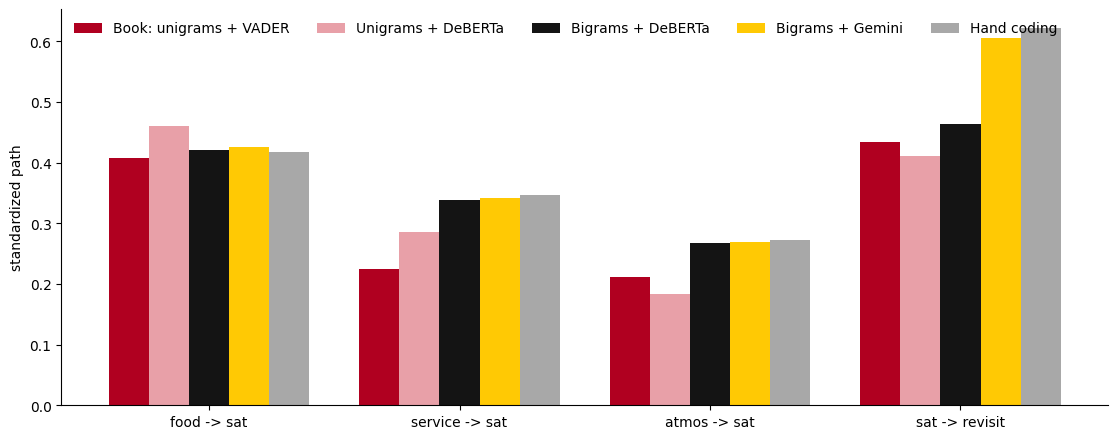

In [13]:
cols = ["food -> sat", "service -> sat", "atmos -> sat", "sat -> revisit"]
colors = ["#B00020", "#E8A0A8", "#141414", "#FFC904", "#A8A8A8"]
x = np.arange(len(cols)); w = .16
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, (name, r) in enumerate(paths[cols].iterrows()):
    ax.bar(x + (i - 2) * w, r.values, w, label=name, color=colors[i])
ax.set_xticks(x); ax.set_xticklabels(cols); ax.set_ylabel("standardized path"); ax.legend(frameon=False, ncol=5, loc="upper left")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## Take-aways
1. **Theory first.** The constructs and the model come from the restaurant quality model, before any AI runs.
2. **Bigrams decide the construct.** A keyword with two meanings, such as "table", sends a sentence to the wrong construct and biases the paths.
3. **Judge the construct, not the review.** An ABSA model judges each construct in its own sentence. A lexicon reads words, not meaning.
4. **Validate each step, construct by construct.** The hand-coded sample shows where each tool is weak, and the paths show what that costs.

*Notebook prepared for the EMEA CHRIE Research Webinar. Data: Maple City (synthetic), from* Analyzing Online Reviews with AI *(Park, 2026), Chapters 5 and 10.*
